# 04-2　重力波：親手從 LIGO 的真實數據裡找出黑洞合併

**前置**：[00-4 觀看前須知 第 8 章](../00_basics/04_before_general_relativity.ipynb)、[04-1 史瓦西時空](01_schwarzschild.ipynb)

1916 年，愛因斯坦從他的方程式算出：**時空本身可以像水面一樣起波紋**，以光速傳播。但他認為這種波太微弱，人類永遠量不到。

**2015 年 9 月 14 日 09:50:45（UTC）**，美國兩座 LIGO 偵測器同時記錄到一個訊號：
13 億年前，兩個黑洞互相繞轉、合併，發出的重力波剛好掃過地球。這是人類**第一次直接偵測到重力波**，2017 年諾貝爾物理獎。

這一課用 LIGO 公開的**原始數據**（gwosc.org），一步一步：

1. 下載兩台偵測器的數據，看看原始數據長什麼樣（什麼都看不到）
2. 分析雜訊的頻譜
3. **白化 + 帶通濾波**，讓訊號浮出來
4. 比對兩台偵測器的**時間差**，確認訊號以光速傳播
5. **頻譜圖**：看見頻率上升的「啁啾」
6. **模板比對**：估算黑洞的質量
7. 證明它們**只能是黑洞**
8. 把重力波**變成聲音**

> 第一次執行會從 gwosc.org 下載約 2 MB 的數據，存在 `data/` 資料夾，之後就不用再下載。

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import requests
import h5py
from scipy.signal import welch, butter, sosfiltfilt, spectrogram
from scipy.signal.windows import tukey
from scipy.interpolate import interp1d
from IPython.display import Audio, display

plt.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]  # 中文標籤
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

G, c, M_sun = 6.674e-11, 2.998e8, 1.989e30

## 步驟 1：下載真實數據

LIGO 有兩台偵測器：**漢福德**（H1，華盛頓州）和**利文斯頓**（L1，路易斯安那州），相距約 3000 公里。
每台偵測器都是一個 L 形、每邊 4 公里的雷射干涉儀，量的是兩條手臂長度的相對變化，叫**應變** $h$。

我們下載事件前後共 32 秒、每秒取樣 4096 次的數據：

In [2]:
BASE = "https://gwosc.org/eventapi/json/GWTC-1-confident/GW150914/v3/"
FILES = {"H1": "H-H1_GWOSC_4KHZ_R1-1126259447-32.hdf5",
         "L1": "L-L1_GWOSC_4KHZ_R1-1126259447-32.hdf5"}
DATA_DIR = os.path.join("..", "data")
os.makedirs(DATA_DIR, exist_ok=True)

strain = {}
for det, fn in FILES.items():
    path = os.path.join(DATA_DIR, fn)
    if not os.path.exists(path):
        print(f"下載 {det} ...")
        resp = requests.get(BASE + fn, timeout=120)
        resp.raise_for_status()
        with open(path, "wb") as f:
            f.write(resp.content)
    with h5py.File(path, "r") as f:
        strain[det] = f["strain/Strain"][()]
        gps_start = f["meta/GPSstart"][()]
        dt = f["strain/Strain"].attrs["Xspacing"]

fs = int(round(1 / dt))
N = strain["H1"].size
t_event = 1126259462.422          # 事件時間（GPS 秒）
t = gps_start + np.arange(N) / fs - t_event   # 以事件為 0 的時間軸
print(f"取樣率 {fs} Hz，每台 {N} 個點（{N / fs:.0f} 秒）")

取樣率 4096 Hz，每台 131072 個點（32 秒）


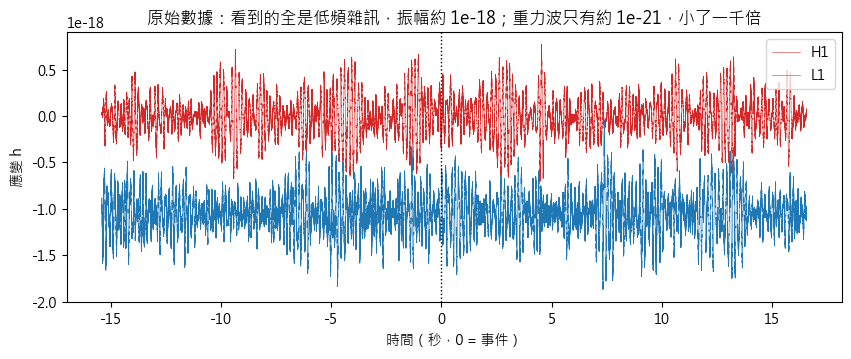

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for det, col in [("H1", "C3"), ("L1", "C0")]:
    ax.plot(t, strain[det], col, lw=0.4, label=det)
ax.axvline(0, color="k", ls=":", lw=1)
ax.set_xlabel("時間（秒，0 = 事件）")
ax.set_ylabel("應變 h")
ax.set_title("原始數據：看到的全是低頻雜訊，振幅約 1e-18；重力波只有約 1e-21，小了一千倍")
ax.legend(loc="upper right")
plt.show()

**什麼都看不到。** 原始數據被巨大的低頻雜訊主宰（地面振動、海浪、溫度變化），重力波藏在裡面，小了一千倍。

## 步驟 2：雜訊的頻譜

把數據拆成各種頻率（00-2 第 5 章的傅立葉轉換），看雜訊在每個頻率有多大。這叫**振幅頻譜密度**（ASD）：

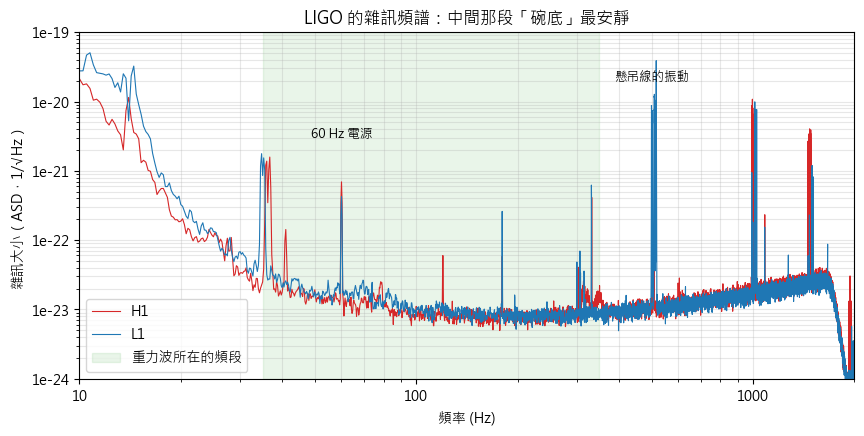

In [4]:
freqs = np.fft.rfftfreq(N, 1 / fs)
asd = {}
fig, ax = plt.subplots(figsize=(10, 4.5))
for det, col in [("H1", "C3"), ("L1", "C0")]:
    f_w, psd = welch(strain[det], fs=fs, nperseg=4 * fs)
    asd[det] = np.sqrt(interp1d(f_w, psd)(freqs))
    ax.loglog(f_w, np.sqrt(psd), col, lw=0.8, label=det)
ax.axvspan(35, 350, color="C2", alpha=0.1, label="重力波所在的頻段")
ax.set_xlim(10, 2000)
ax.set_ylim(1e-24, 1e-19)
ax.set_xlabel("頻率 (Hz)")
ax.set_ylabel("雜訊大小（ASD，1/√Hz）")
ax.set_title("LIGO 的雜訊頻譜：中間那段「碗底」最安靜")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"1e{np.log10(v):.0f}"))  # 避開數學字型缺負號
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.legend(loc="lower left")
ax.grid(alpha=0.3, which="both")
for f0, label in [(60, "60 Hz 電源"), (500, "懸吊線的振動")]:
    ax.annotate(label, (f0, 3e-21 if f0 == 60 else 2e-20), fontsize=9, ha="center")
plt.show()

**觀察**：

- **低頻（< 30 Hz）**：雜訊非常大，主要是地面振動。
- **高頻（> 500 Hz）**：雷射本身的**量子雜訊**（光子的散粒雜訊，02 單元的量子力學）。
- **中間的「碗底」**（約 50–300 Hz）最安靜，剛好是恆星質量黑洞合併的頻段。
- 尖尖的突起是特定的干擾源，例如美國電網的 60 Hz 和它的倍頻、吊著鏡子的懸吊線振動。

**有趣的一點**：LIGO 靈敏度的極限之一來自**量子力學**的不確定性原理。量重力波（廣義相對論）的儀器，被量子力學限制住了。

## 步驟 3：白化 + 帶通濾波

00-4 第 8 章的方法：

1. **白化**：每個頻率都除以那裡的雜訊大小，讓所有頻率的雜訊「一樣大」。這樣雜訊特別大的頻率就不會蓋過一切。
2. **帶通濾波**：只保留 35–350 Hz。

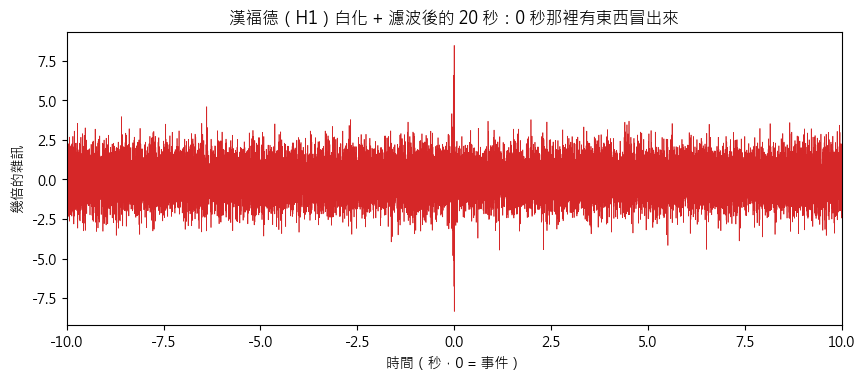

In [5]:
window = tukey(N, alpha=0.1)       # 邊緣平滑降到 0，避免 FFT 在兩端產生假訊號
bandpass = butter(4, [35, 350], btype="bandpass", fs=fs, output="sos")


def whiten_bandpass(x, asd_det):
    white = np.fft.irfft(np.fft.rfft(x * window) / asd_det, n=N)
    return sosfiltfilt(bandpass, white)


clean = {det: whiten_bandpass(strain[det], asd[det]) for det in strain}
noise_level = {det: clean[det][np.abs(t) > 3].std() for det in clean}
clean = {det: clean[det] / noise_level[det] for det in clean}     # 換成「幾倍雜訊」的單位

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t, clean["H1"], "C3", lw=0.5)
ax.set_xlim(-10, 10)
ax.set_xlabel("時間（秒，0 = 事件）")
ax.set_ylabel("幾倍的雜訊")
ax.set_title("漢福德（H1）白化 + 濾波後的 20 秒：0 秒那裡有東西冒出來")
plt.show()

雜訊被壓成均勻的「沙沙聲」之後，**在 0 秒的位置出現一個明顯高出雜訊的尖峰**。放大來看：

## 步驟 4：兩台偵測器的時間差

如果這是真的重力波，它應該：

- 在兩台相距 3000 公里的偵測器**幾乎同時**出現
- 時間差**不超過光走 3000 公里的時間**（約 10 ms），因為重力波以光速前進

另外，兩台偵測器的手臂方向不同（利文斯頓轉了大約 90°），所以訊號會**上下顛倒**。

L1 往後移 7.3 ms 並翻轉之後，和 H1 最吻合
光從利文斯頓跑到漢福德最多需要 10.0 ms → 時間差 7.3 ms 小於它，符合以光速傳播


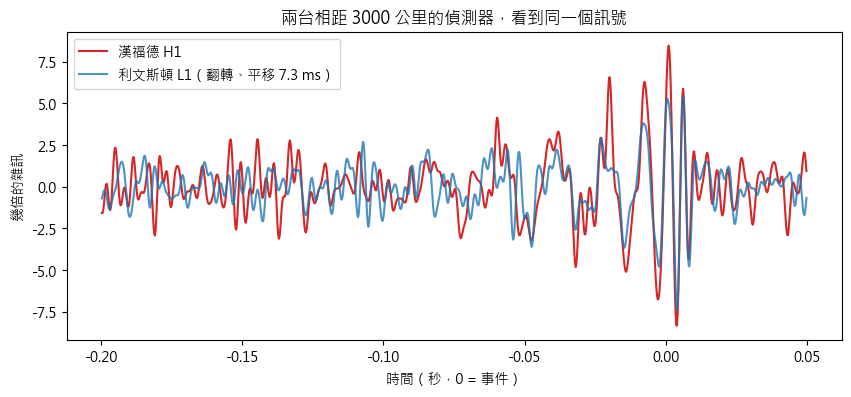

In [6]:
zoom = (t > -0.2) & (t < 0.05)
lags = np.arange(-int(0.012 * fs), int(0.012 * fs) + 1)
match = [np.sum(clean["H1"][zoom] * -np.roll(clean["L1"], k)[zoom]) for k in lags]
best_lag = lags[int(np.argmax(match))]
delay_ms = best_lag / fs * 1000
light_ms = 3002e3 / c * 1000

print(f"L1 往後移 {delay_ms:.1f} ms 並翻轉之後，和 H1 最吻合")
print(f"光從利文斯頓跑到漢福德最多需要 {light_ms:.1f} ms → 時間差 {abs(delay_ms):.1f} ms 小於它，符合以光速傳播")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t[zoom], clean["H1"][zoom], "C3", label="漢福德 H1")
ax.plot(t[zoom], -np.roll(clean["L1"], best_lag)[zoom], "C0", alpha=0.8, label=f"利文斯頓 L1（翻轉、平移 {delay_ms:.1f} ms）")
ax.set_xlabel("時間（秒，0 = 事件）")
ax.set_ylabel("幾倍的雜訊")
ax.set_title("兩台相距 3000 公里的偵測器，看到同一個訊號")
ax.legend(loc="upper left")
plt.show()

**兩條曲線幾乎重疊。** 兩台完全獨立、相距 3000 公里的儀器，在 7 毫秒之內看到同一個波形，**頻率越來越高、振幅越來越大，然後突然停止**。

這就是兩個黑洞最後零點二秒的「死亡螺旋」：繞得越來越近、越來越快，最後合併成一個。

## 步驟 5：頻譜圖，看見啁啾

**頻譜圖**同時顯示時間（橫軸）和頻率（縱軸），顏色代表那個時刻、那個頻率有多強：

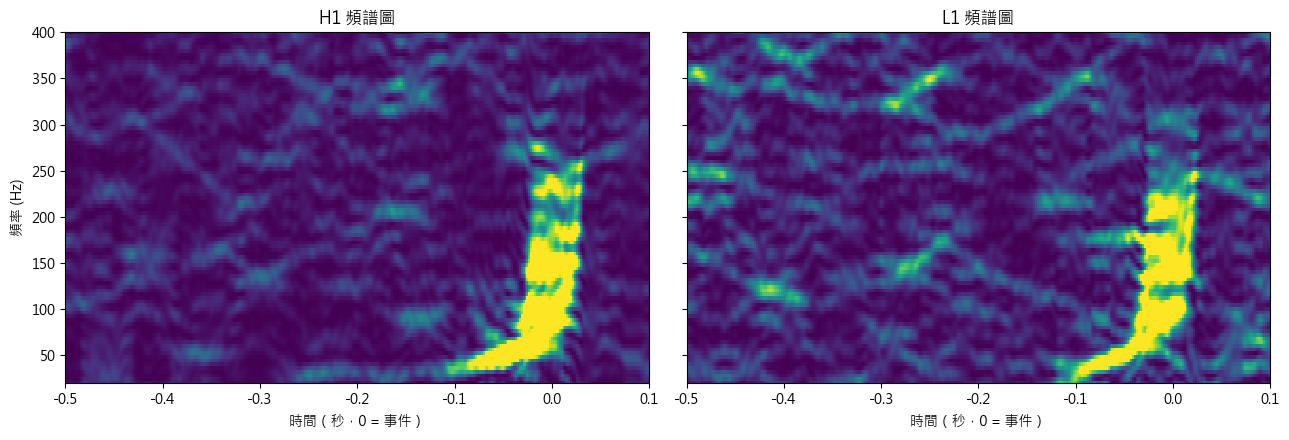

In [7]:
white_only = {det: np.fft.irfft(np.fft.rfft(strain[det] * window) / asd[det], n=N) for det in strain}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, det in zip(axes, ["H1", "L1"]):
    seg = (t > -1) & (t < 0.5)
    f_s, t_s, S = spectrogram(white_only[det][seg], fs=fs, nperseg=256, noverlap=248, nfft=1024)
    ax.pcolormesh(t_s + t[seg][0], f_s, S, shading="auto", cmap="viridis", vmax=np.percentile(S, 99.8))
    ax.set_ylim(20, 400)
    ax.set_xlim(-0.5, 0.1)
    ax.set_xlabel("時間（秒，0 = 事件）")
    ax.set_title(f"{det} 頻譜圖")
axes[0].set_ylabel("頻率 (Hz)")
plt.tight_layout()
plt.show()

最後零點幾秒，有一道亮帶**從約 35 Hz 往上掃到約 250 Hz**，然後消失。這就是 00-4 第 8 章說的「啁啾」。
（頻譜圖的時間和頻率解析度互相牽制，這又是一個傅立葉版的不確定性原理，和 00-2 第 5 章同一個數學。）

## 步驟 6：模板比對，估算黑洞的質量

廣義相對論預測：兩個天體互相繞轉時，重力波的頻率上升速度只由一個組合決定，叫**啁啾質量**

$$\mathcal{M} = \frac{(m_1 m_2)^{3/5}}{(m_1 + m_2)^{1/5}}$$

在最簡單的近似下（遠離合併時），頻率隨時間的變化是

$$f(t) = \frac{1}{8\pi}\left(\frac{5}{t_c - t}\right)^{3/8}\left(\frac{G\mathcal{M}}{c^3}\right)^{-5/8}$$

$t_c$ 是合併時刻。$\mathcal{M}$ 越大，頻率上升得越快。

**模板比對**（matched filtering）：產生一系列不同 $\mathcal{M}$ 的理論波形（模板），和數據逐一比對，看哪一個最吻合。LIGO 實際上就是這樣找訊號的。

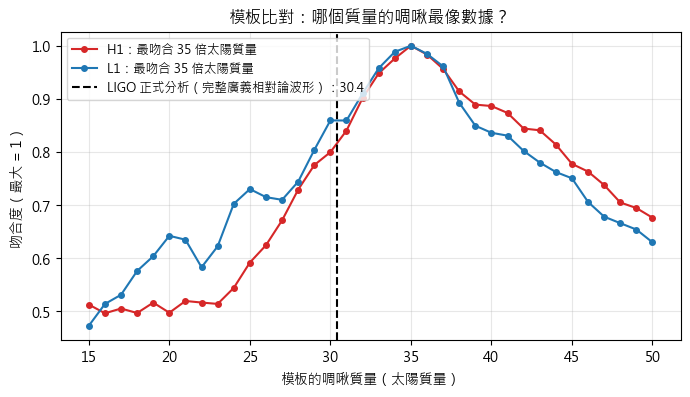

In [8]:
def chirp_template(Mc_sun, tc, f_max=150):
    # 最低階（牛頓近似）的啁啾波形：回傳 cos 和 sin 兩個版本，涵蓋所有可能的相位
    tau_m = G * Mc_sun * M_sun / c**3
    tt = tc - t
    ok = tt > 0
    f = np.zeros(N)
    f[ok] = (5 / tt[ok]) ** (3 / 8) * tau_m ** (-5 / 8) / (8 * np.pi)
    keep = ok & (f > 25) & (f < f_max)
    phase = np.zeros(N)
    phase[ok] = -2 * (tt[ok] / (5 * tau_m)) ** (5 / 8)
    return np.where(keep, f ** (2 / 3) * np.cos(phase), 0), np.where(keep, f ** (2 / 3) * np.sin(phase), 0)


def best_match(det, Mc_sun):
    # 白化後的數據和白化後的模板做交叉相關（用 FFT 一次算出所有時間平移），回傳事件附近的最大吻合度
    hc, hs = chirp_template(Mc_sun, tc=0.0)
    wc, ws = whiten_bandpass(hc, asd[det]), whiten_bandpass(hs, asd[det])
    D = np.fft.rfft(clean[det])
    corr = np.hypot(np.fft.irfft(D * np.conj(np.fft.rfft(wc)), n=N),
                    np.fft.irfft(D * np.conj(np.fft.rfft(ws)), n=N)) / np.sqrt(np.sum(wc**2))
    shift_t = np.where(np.arange(N) < N // 2, np.arange(N), np.arange(N) - N) / fs
    near = np.abs(shift_t) < 0.05
    return corr[near].max()


masses = np.arange(15, 50.5, 1.0)
fig, ax = plt.subplots(figsize=(8, 4))
for det, col in [("H1", "C3"), ("L1", "C0")]:
    scores = np.array([best_match(det, M) for M in masses])
    ax.plot(masses, scores / scores.max(), "o-", color=col, ms=4, label=f"{det}：最吻合 {masses[np.argmax(scores)]:.0f} 倍太陽質量")
ax.axvline(30.4, color="k", ls="--", label="LIGO 正式分析（完整廣義相對論波形）：30.4")
ax.set_xlabel("模板的啁啾質量（太陽質量）")
ax.set_ylabel("吻合度（最大 = 1）")
ax.set_title("模板比對：哪個質量的啁啾最像數據？")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
plt.show()

**我們只用最簡單的牛頓近似模板**，估出的啁啾質量約 30 多倍太陽質量，和 LIGO 正式分析的 30.4 在同一個範圍。
差異來自模板太簡單：接近合併時，兩個黑洞的速度達到光速的一半以上，牛頓近似完全失效，必須用超級電腦**數值求解愛因斯坦方程式**才能算出準確的波形。

LIGO 的完整分析結果：兩個黑洞分別是 **36 和 29 倍太陽質量**，合併成一個 **62 倍太陽質量**的黑洞。

## 步驟 7：它們只能是黑洞

**論證**（LIGO 2016 年論文裡的同一個推理）：

1. 訊號最後的重力波頻率約 150 Hz，對應的**軌道頻率**是它的一半（每繞一圈發出兩個波峰），約 75 Hz。
2. 用 00-1 的克卜勒定律，從軌道頻率和總質量算出**兩者的距離**。
3. 和兩個天體的大小比較。

In [9]:
m1, m2, m_final = 36, 29, 62
M_total = (m1 + m2) * M_sun
f_gw = 150.0
omega_orb = 2 * np.pi * f_gw / 2
separation = (G * M_total / omega_orb**2) ** (1 / 3)

rs1, rs2 = 2 * G * m1 * M_sun / c**2, 2 * G * m2 * M_sun / c**2
print(f"重力波 {f_gw:.0f} Hz → 軌道每秒繞 {f_gw / 2:.0f} 圈")
print(f"克卜勒定律 → 兩者距離只有 {separation / 1000:.0f} km")
print(f"兩個黑洞的史瓦西半徑：{rs1 / 1000:.0f} km + {rs2 / 1000:.0f} km = {(rs1 + rs2) / 1000:.0f} km")
print(f"軌道速度約 {omega_orb * separation / 2 / c:.2f} c")
print()
print("可能的候選：")
print(f"  兩顆普通恆星（半徑數十萬 km）  → 早就撞在一起了")
print(f"  兩顆中子星（每顆最多約 2–3 倍太陽質量）→ 不夠重")
print(f"  兩個黑洞                          → 唯一可能")

重力波 150 Hz → 軌道每秒繞 75 圈
克卜勒定律 → 兩者距離只有 339 km
兩個黑洞的史瓦西半徑：106 km + 86 km = 192 km
軌道速度約 0.27 c

可能的候選：
  兩顆普通恆星（半徑數十萬 km）  → 早就撞在一起了
  兩顆中子星（每顆最多約 2–3 倍太陽質量）→ 不夠重
  兩個黑洞                          → 唯一可能


65 倍太陽質量，擠在一個只有幾百公里的範圍裡，以約三成光速繞轉（合併前最後一刻超過一半光速）。**只有黑洞做得到。**
這是人類第一次「看到」兩個黑洞，也是第一次證實雙黑洞系統真的存在。

**能量**：合併前總共 65 倍太陽質量，合併後剩 62 倍。消失的 3 倍太陽質量，依照 $E = mc^2$（03 實驗 7）全部變成了重力波：

In [10]:
E_gw = (m1 + m2 - m_final) * M_sun * c**2
L_sun = 3.828e26
print(f"釋放的能量 = 3 M☉ c² = {E_gw:.1e} J")
sun_lifetime_energy = L_sun * 1e10 * 3.156e7      # 太陽以目前亮度發光 100 億年
print(f"約是太陽一生（100 億年）總發光量的 {E_gw / sun_lifetime_energy:,.0f} 倍")
print(f"這些能量在約 0.2 秒內釋放，峰值功率約 3.6e49 W，比可觀測宇宙中所有恆星的光加起來還大")

釋放的能量 = 3 M☉ c² = 5.4e+47 J
約是太陽一生（100 億年）總發光量的 4,439 倍
這些能量在約 0.2 秒內釋放，峰值功率約 3.6e49 W，比可觀測宇宙中所有恆星的光加起來還大


## 步驟 8：把重力波變成聲音

重力波的頻率（35–250 Hz）剛好落在**人耳聽得到的範圍**。把白化、濾波後的數據直接當成聲音播放：

（訊號只有零點幾秒，注意聽最後那一聲短促的「**啾**」。因為頻率偏低，用耳機會聽得比較清楚。）

In [11]:
seg = (t > -2) & (t < 0.5)
audio = clean["H1"][seg]
audio = audio / np.abs(audio).max()
display(Audio(audio, rate=fs))

# 也存成 wav 檔，可以用任何播放器播
from scipy.io import wavfile
wav_path = os.path.join(DATA_DIR, "GW150914_H1.wav")
wavfile.write(wav_path, fs, (audio * 32767).astype(np.int16))
print(f"已存成 {os.path.abspath(wav_path)}")

已存成 D:\Python\Physics\data\GW150914_H1.wav


## 總結

| 步驟 | 結果 |
|---|---|
| 原始數據 | 什麼都看不到，雜訊大一千倍 |
| 雜訊頻譜 | 中頻最安靜；高頻受量子雜訊限制 |
| 白化 + 濾波 | 0 秒處冒出明顯的訊號 |
| 兩台偵測器 | 時間差約 7 ms（< 光走 10 ms），波形一致 |
| 頻譜圖 | 35 → 250 Hz 的啁啾 |
| 模板比對 | 啁啾質量約 30 多倍太陽質量（LIGO：30.4） |
| 只能是黑洞 | 65 倍太陽質量擠在幾百公里內 |
| 能量 | 3 倍太陽質量在 0.2 秒內變成重力波 |

**意義**：

- 證實了重力波的存在（愛因斯坦預言之後 100 年）
- 第一次直接觀測到黑洞，而且是兩個黑洞的合併
- 合併過程中速度接近光速、時空劇烈彎曲，廣義相對論在**強場**下仍然完全正確

**和大問題的關係**：這次合併中，兩個黑洞的視界融合成一個。霍金早在 1971 年就證明：在廣義相對論中，**視界面積只能增加不能減少**，就像熱力學的熵。
LIGO 的數據後來被用來檢驗這個「面積定理」，結果吻合。視界面積就是熵：這正是 05 要討論的、廣義相對論和量子力學在黑洞上的交會點。

## 練習

1. 步驟 3：把帶通濾波改成 20–500 Hz，訊號還看得清楚嗎？為什麼？
2. 步驟 6：把 `f_max` 改成 250 Hz，最吻合的質量會怎麼變？為什麼越接近合併，牛頓模板越不準？
3. 步驟 7：如果是兩顆 1.4 倍太陽質量的中子星，啁啾到 150 Hz 時兩者距離多遠？中子星半徑約 12 km，它們撞到了嗎？